# LAB 09 — MLP

**Notebook Google Colab | Học máy ứng dụng | Lab 09**

Nội dung theo tài liệu `Lab09_MLP.pdf`: **phần thực hành theo từng bước + giải 6 bài tập cuối bài**. Các lệnh có chú thích và in kết quả để tiện chụp màn hình.

**Cách sử dụng:** mở tệp `.ipynb` bằng Google Colab → **Runtime → Run all**. Chạy lần lượt từ đầu; dữ liệu CSV được khôi phục tự động trong bước chuẩn bị, không phải tải CSV bằng tay. Ảnh và bảng kết quả được xuất ra thư mục `ket_qua/`. Những kết quả mô hình hoặc thời gian chạy có thể thay đổi theo phiên bản thư viện hoặc máy.

## Chuẩn bị — thư viện, dữ liệu và thư mục kết quả

Bộ dữ liệu lấy trực tiếp từ ZIP người dùng cung cấp, được nhúng vào notebook để mở bằng Colab là chạy được.

In [1]:
# Chuẩn bị dữ liệu gốc đính kèm (tự giải nén, không cần upload riêng).
import base64, io, os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

_DATA_BASE64 = "UEsDBBQAAAAIAKhRNl3neLqEtQEAAM0DAAAQAAAAZGF0YS9naWFfbmhhLmNzdkWTTW5CMQyE90jcJIriOLGd0yDUVoUNVGp7/844QJffG/+M7bz368ft9HN9u5Tv++nrcr99lp/f+/V0u5zL5/V8POiss0iRKFob0KuVXhwUfjyMVQewtzJqn8kNLAa2xMXkjvC1jofZEA5eDB9gqcJw3+FTE3uZtQVwIhsAcVE1OHkEB+VIWRrCh704KMOKteqUB2ShvOBcSiJam1RlL1afkO1Rnbp2sGY4B1vxL9Nb78lWlJOgnCaznEzqWIzNGtQVbIh32WaNjPbecq2tWBXKClSWRx1J+TWbU+97MyynM+Pt2W7GiwfTk7Dx0ml2kUeyF68Cb27YjHJ0DBHJPNoC8qa+cjRk7/BozxtjppF6jhqInyn7ngzVcOPouamG7I7iMZAN2yWqYLCI7JXFsfXA+HuNXlVTlr1m5yDhucXeHk5TVj4BWH1hZy+Fs8WbDi4deUhfuidhr42cWxjuSF9WuTJamzC+PJ2mNZ588T0pd+7ZXFpPNxnfybrb483VNvhhZMEAL3/yTlAi38zAGfDTAEW2nQE23x/yhGDPgH1GQzrtivh+JIEAWfzAH2RwIPx2WO4fUEsDBBQAAAAIADyAPF2FZ7Cc5QcAAGUUAAAXAAAAZGF0YS9oYWlfdmFuZ190cmFuZy5jc3ZVWDmS7cgN9CdibtLTgR2o48iTJVvHF1b+UHvNx0JhSSQS/C/+/Jd+/vPvf/3n77/+gV8ijR/8BWb6gb//gl8P45/8QV8+wX4C3k84tJ/QLwbqD/xa/s0rz4R/+o0yUqddJB8gBY9Zi/fKCGD0Gfw1f2UEQHWMqMQrI/ZszmAdwDg/9D3P31XD9hZiLxMucwJ/GdKD/kF9DmFIhYdv/RD2yCMZyrkqzFZmnd4YUbIx4qDjKr3oBFR8OIdIyhf3TE3fw2aVATXCuYhZXt6MyGOVQjoBgsKX10cdIT5fs8Fa3rFuBsBf/U9P35wxiK6FPdzUA0IVEPmLJ6uUlkD3Yng8F7PghqPRxTHzeeXtK0S8voWD9RNgXN/QJAvxyzKnGhd1k5vSJW5wQsZzkQPTJI7jrIR2LqEOjzdAFWOGsRHhg0pl5uldWqyhIpuXf9ILy2AyDU60YXcp8h2RqCcJ0lfeAeE6Aw0nsEdnVaQLryiXOsJ6wn5FzN/qGg1YbJi3b/CQ1hMkqDMSvghLoPdN2UcxAVFQm+20T+aqemn265eMrJ5kbje5Wr01QNvSJ6Dq6icHDg5sDEocWkyqgSJowU/ScDLH800Qp6yA10MxvthZSTRW4gidzhWqwiNMy+SND7uG6oabhfxtEQT7UkVf76itM0x5Z5qxOLvkfUZxMQedfbK72KGbTFQWpyTdqtGZGDhpNXaGbG/OvCkhkl9qg7hq6Hie8QBOHw6+0nttNLHxXpTVbApIB95QHkO1TGBipf+HKLooght0ZXdIN7NfYyZJNvadlt/4UYeT4Lmqy2BS4JpM/dU9z3QrBmJtl+2aFxrnL4u6idYGCovLulLgbBKMdZZU6+Z4cURDrxJWQNxcJzirxbLfNyDLpDT10FJCtn8zHMLRb5JTFzAvlOk5eOV3WrEFbXrf3ZFhLOnhmwcqS0+GA3SXJYRQa3pyPuRgtn8WhQduBUXUSYr4NrcPRZNsEkBoHjDt+IBpHxq2Sl9JqGfWEQRZ9BFTkE0TFEYKqfJRRGjlifGmBdVAq1MiO9hofcHi6sk/4DJ9XKFlmlfUF3LD/BXYIJCxyVT0SPBZD93XPd3smtAavoXvndfkb3DMvnXOGXeYC+3J7PYWP+id3Wz7HRiuOt5SnF2Ltqsqeg3P7Z7zN6wDmsZ18l2vAPZNjMcbwTPdcMd1QneGgYt/N3kDU3gTYThRUkwmqk5NyqlY3sZk0GMyLI7UmjIy+sNUdmVXyc2uAmzdjqSw+UTpCJIeNjPdQNU2vrh73jNFX2xL5wgpGzkkL5nzP4p/TYNNpnLdWrxRIccplFf6o2lwRm0js1PJ9FmxmvFkcAE+xO3fy8GQYqaC5U8S6hD6lV7Q6OdmTQfoUA+wWnriaT9rbpzy8ZEB71M+6a1XMwLfzYnDCtpoBnjNxOg8Ocs3nSk6pHcqLENrTcHbr/Ka+FAm5uwZ6wfCsOMBMo6yjXHdadCkzCsLcojVNOg+O+qw9GHH6HIJSKPd3qJd3nAJLAuwrFxS3/GtxWHtLKzVMG33Q/mcqyxXV9AyIfNCBS9xqY6aS27o15SZJsp0L8AgJi8w6S7m5qGJpaTKbdMwsOCX/xZ8rgexEhHdSp+a49Ge/iwWYtK8kCjavEjTEWZTLAk/Gd8qUSs9behG8Y9qGb1xmoVbwOekPdHPzf5U/D0MUC3WVpG/ArUIg2+qROE1aS5uokszgnHIVawVl3ms71R01wXSo56YIt7IpxrCpU7oEzk11gpMttOgmTd5Hf4gv3EhBnuNFqqab2lBq4uu3GF2Oqez48rHAFEiqXIfeDOxWTSBgGs41e1AnTZv7CMmEnDHwNKaNPvjO9TTq9Xncn+vNOmd2glg8UHyTeNUFb0v1co1aSi8Fja7KzrI1rcpPq9zs3FL/dGOwFKZ2EL73RqAvVGV7p7kE/YMco7bLmKyFLHdIiliRhtdbnM0dAowbmuB4sfUTHY5CeCxctm3Jc5UT9ftPV/Q1oYOYKUod+r1oFMkJ8lUmwCDPoH8tBXmG8nZe0ULo6T+e6UEWC1ctxMkqxZAoYTYUEh3aHLoMWQuZz2x3qdsGVYc+vUf7aq07Yc1nivJtzgRFsYSltPmiVgdKY+x1YUmzCTD2y99Rk269828RGMZ0RvJKTOapuy6LfV7BZPzZcVkUVwrC/ArhPfCKUanQ1bvtEybTtFhXbFjvyxKL2zyjTBZomW7LwLODU8wO4aPGRvg8Cm/HZ/vSphKv7LtrRu2tYfQv31SCzE1sZZAkn0q6BzNqzGy31aDvlPZPqqjl6GNoNWMmR7jzy7iI8eKzmvVyTeQ+RYn0dkEr4tzgvcqRX6aY9khR8H1cSmUIm/ZfKeRYWK2D5MlDlvc/b/uxj98wd3jmQRYPc/dtXjztvVcrjd80c03HsK3PUoUvQZm1+4DHLWvwqcWZGhK7AQS9JytBC/P9peZlDizlFfrvWlR+b7PeJ8AjGuNyWLW5NvKqcvFeJH0xgp/RPlM8yxa7PTKsDs+315Bnj3ev2q+2oTro8C3gneH1y4YfxDau5h+q/JUT3tWzpzBXlXS2CKJaAePvMMw1ZZUyD3V5TJLBdCNvFywe5NX/uQ1tBADwuPh/qzQC+/nMPX3MJZTVTTSXiU+BpAdt6NuSj7MVzdXW/aKGRJJUUs92aIzfMi+z1KzkYFemD0f/mm9uFCgTjC9kRz/A1BLAwQUAAAACAA8gDxdkA18cd4CAAD9BwAAGgAAAGRhdGEvc2luaF92aWVuX21vX3JvbmcuY3N2VVXLbh0xCN1Hyp9YIwwGe77mKmqj9KpKrio1i/59AYPHdzGLYXgcDgfm4/64Pb7Kz/v75+3j/v12+/2v/Ph1v/29v3+XP/r++fh6feGDCx1QGBgKvL7UU19En94BSlVDs5ejFxzhUdVAR50eZgDNwccoZB4agqSGcWBpHIauIcMSn9PAHiGltVXVDK0wzaqn12gF63RAM5yaUhgypdXQKJwpHfhQWA0mLET9KsdZpIeHVe1qoBE52HtVGNkrORuiva7W9IMaW5sGq4hKBuF8t8b4oELRaZUA7jjBU0JpaqBgC8E7aaWds6ixZw79XBEGcyi/T4RTEZoGqwH67q2bw/DWsZBw9gE+VQy+TwchpUfnEjW5BijxPnTIwQS24JuTvKwhWWNOXZ8MGY5bnxhR7SElTJwU5HBOtbu2FFtPnBMXRqdYHVctPC4Hk1qvOQ9Nb9/5KaCvgXTnqpee+p4zr1PwE+WUSRrYMYw1QdWR2sHZhBwyO2xJw/AYzVPDUJ0tTZLKwlAW1SccUmRseyYmlBpLMwnWshefU789PDypizoM4PyqQxDuUzS62nhagXYpBUJbCMsDXOHJuB8Hw0lwzUyc0Zj7GXqlFII7qBppuw/WWaZ0Rp32bao2k55r10Ovi3EMj1waJCeYSidOFJPxdXMk58p8DcnWJm8KRxEJaYSA+xIw+LLzvFowt8io6HQdA1MKx3dfbStLjXOm7KdSZEaQnxM9FzEgCFX0uFm+Zb4yDa4MvGEIj1oInraMSsOt8W5FkqupG2207gpXh71xPxFtscsTRqri9InhWitvtW8n3nfCpIbCV1VxIcHaxKbvjbZeLYXkCGevetcCeHNtaoSsiNAJLllMwXMIBykEn8ry3bXCsNHX7K4lW7nulDnPODkDYInTUNDzv2q7+eARqEPbdMD2owmP5jvFSwbDU+pBj79Ijb8MxsXHkE3LwylRsm1XzY9H6oZjB/OQ/gdQSwMEFAAAAAgAoYk8XYqX8lQHCgAAxxsAAAwAAABkYXRhL3hvci5jc3ZNWUmSGEkKvLdZ/6SmjJ3gOXObU5/7+UOwREoXqVKZsYDj7lD/4s+/9PPP//77z99/wS85x89/4FcM5Af+/iv/GXjwPgqz+MH7kpHpD/weUu0HhMz5QHRegON0X3DA+YLRa40QvcvCr6OcesJ0+kl+zfeJyfF5hywPkatRrXuPBWD3HVSxeRTCch+5ovRmLHh3p5B5QAy1FzFZrxz3/+6VcLZiR8wHDDBXYLcKBOWfCYRTnHtL4f4GFOpS7KHzCtC5gXCPfuVYx46OSD9B4XrCarMMnlN3YpLdidDuTn5gF1ZRv3cS27Qcvpc001lGPT+/b2YyJnxa8Tw3fP0Nk1cgLO8/4YOIe2KNDs1dgE9d68SGGAMqFgY8Tw6eiwA08PlK4C6Qsd/zGdyAnpOn6m/Iojb3MyEmPYUSlV0WMe6T3G4/AoC6FUos1gQqdQHUD054nQ48JuqKCcz6WGlTde7p1PHdye/RE+fzjRDdOBwTnDfc6waiZ/ZRuUkJ1kVjONxVPYtmYGVUZ0PZ8DrQDVTCfpNSp0yQi+8VC77K+0ZG+e5zxPckYn7PCgOrCpRUBRq9Io26zaCMqHOYxcF9euEjXcXnBel+Aq+Iz03Hza35vGKHrJ/YgoNz58oHxxRXFvANE5LoHvdQAU/RrN9xt8amHN5i0saU0J4Q/VbaL2a5D2lgSK384pAFXJu77CtsVeo6ayRX1RtkOJnHwkAWmU8aLXmsYAiBG81LOInpiBdN7iTp5hGtkGkaG4k40KWdxbRVIeRFIrppES1UCWxyz/He/aUqWaWDfHDPQ3y0QQ8bU2h4htJiXDsRfIM9m936LNacu2fUrVKMe41K3z17nE3oMJSxbLIM6qrUCM1XWAv4l5QGKbWKhA10nPowCrp84OhafAC4BRaVmmSsDTPBidIRGFFAumKQ7G5bHIZY0H+FLE3Lhwi35ipXKHS2LFt99NVcaOkVeuyybK0jRrqaoR0GiAF/csi9JIHMK0GtWEf10T00RZyzCU/IaMsGP1RctF4o4Mb83Fqp+8dE1KXKFWrPCjEVbJVxY84wwHngOhcM9XcM/J2LKOjmdPmz42VOK2zitTkvAIXwDH+usCXbFlvGx/fFN6i+Vze4Ucj82MJvIeq+aEtM3fDEqm5KQu/EruskHCvIuljDAt+ht8ixqI38FYc18GV1JLJ07nEv+W61nBibMOu6dn4PvWu3xqqfCZ5GMyS/JGRcm8gk9pLk2vxniut1qGXNZfOLx9oxxZJkIqQEvah9zETRpoBvcKToL+E8R7ahChzgXBwXIYYMJgD8/qywxizD1jgSfxbqrp/b8CNRpEbWVgdKF+/BxySUXNzIokdA0ktnnS2wUanL6lkHv7asFGQKutjl3s2XXIKtjIM9/4ZRJ6Q9Dvcnimsm7RquNp045q2qJ84SiWn7O7SJXYakMpDasdTidqZ+VhGV6pLCjwwNO02ksYR0BrHDNkkhzdbrWjla7P4wPlJSwfKkIsE8kH2eJUmh6QYHa0BS68Qrb/My1W5Psb1NF/LSmF5U3yePkcLLJ8qWXOq/lhemgWvaWZ/UPsMHxZdpyM/LP1rJxLLRcIaFbTTLxeTln9GhJhr2Radc7spvkxee+pi2Rd3TZGoLDp8X6ixlC7CPjjY3hq3op3FpTkN/hYHY1vIxcywk4AWLtVVrwUmnyieJeUF+WAZaS/rAMbB/FiiwMZHStGU3FCuDGgdp1D9jmwVVC4Mt/ViZSbZtWsxLxvIsc8sU9mmytusSbc0SXM8aTYVJans4vA6rpMX2UhoFieO6AnmwPed66CK9Eqk4uBGUNrdm+ICtZUyz3jfsTaHPY2Y7VTgK3J8va9/AzANtIfZlJ7I+7PHXUrU5uzkfmzO6rCuVyenVFPoqI0sdS59NzLaJq1d6fi6PXDJDC2g+fZM5l1g5HBB4uuldjkJfHKWsCAfYlj5OEU8+0m3XG5fLhrqqH0gf/SnTEPRT6ExY19ZAfmzufbBGOBXJ2mrSdpHtwJCeJfNuK4nEH39Uo5Rd4MLyRO0UwJ+KV/2RL1+ot4NAfiKOQ5y2WgpYzYY9SdFr6S6uJOaVVPFOG379qrWjEdMneOOC+DlYbIMg8rCaHWuB6mKvd99gnLUr5F1LU8eXDxtFRKvkGZVK+OFdl7FVhK8g9cKBRZXP9yZL9TIsT5vqlfDHGCid4K2/w95BX0t7To8nUgH3luE6ovKHUSq+Fd4uMYqr4vbyfRboFpBhHqSNluo1Xh+pQOWmv8MgVQnr7SS7vACbqvgLOXR8L/lP+TSqw5/2I7dlIPnayxY93fmJcFvaJ5RRAqH6mN6wC+rAU+3QTwR3p3KVJYYryVDVrdvcO4/QrCwCNu2kpk79SBt1B92OKimi+jBbucWyvxnn17wlJ9YB07w9jHQTrewTdAbUn8eN7a+kMJKA3UmSFOnVBjPmuDOG3Ap23W1A4Ymndn+8Pf9ljm4Bzc6WC65BeD6TtOda2V3aK8UZWw15lEloUUup5e3f2MfEPovSgyuitWHcD/hCaMUReubDO7DzEngNxO3gvWWYnzM73EXOj4XOMDrMPSoyPcA5sKyPPfVJRC++RkB5jlyDlLqEfHiP02b3ecnctawYLnlwUwV+2HYrT8183rzzNOEZf3OpGY3QSF191wyXxmCdlfi8pPgO3fh57aFjzwNinQuzT6uPbzLS01W+LdDIfGwPNwuzn+HARV0mp0r0D5/f7jxDskUQ0vxv/ICnWPMTMXmDsrazKa975sRPO5M3RvTx2wrrpQ1H12Inn66tLLDmILtJnJZ7V2ZrM03yugHA5lxQfRZR+va1YNurnrE+CT39RpqXxbxg0xHG2aZBYJpln6uq9XQLyq/3xbJPaqH1pz/cqa/r7+JNZWhr52Maejir/AG9UvxRCtbD15CdSzM3HSe5bZei1CX1XCtPu5ulvpZ+q14+WAFOV7JRE5eeBcFOGKq4sqKe5bNoy6Bynv2uWXDGd7kM2igmotcfYB85o/FMng6CaZlq2p3wNUYylyB4w4Iu8Izg46QZMS8HYLuglOlt4bGpDWy7vDKF1ZrOJQNrAJdVun1WzdTvFHo/gc6Uq36TyBr9E9Ozvjq4pDcwsh7kKa0V8IaT82piAt2745hIzVBlImDVUZWS9lG1e6EdoZctGFi9wWRSkNdkQ76BovU629fuVA3gsSDXrz/iuu7OB48e6hvEREc7vee6xaxl6aHZlgfW3ha4uE9iquh+LSoY7CyG1knXoN3i/aqA18EH7MT4WqJLWWdpSAoYSQ3nG5GVdSlA93FkfjsE9od1qViM/jQfXs4TXyji6eZRz3b0RI289HCPzrxTYe5LQxTNDXEH14vP5jx6nkLbHpCs8Tin7QHFc73IPTaR9W2h43r91UJqZDXT+PXsLSTfoDFteU++z+c8qVx4TDvyf1BLAQIUABQAAAAIAKhRNl3neLqEtQEAAM0DAAAQAAAAAAAAAAAAAAC2gQAAAABkYXRhL2dpYV9uaGEuY3N2UEsBAhQAFAAAAAgAPIA8XYVnsJzlBwAAZRQAABcAAAAAAAAAAAAAALaB4wEAAGRhdGEvaGFpX3ZhbmdfdHJhbmcuY3N2UEsBAhQAFAAAAAgAPIA8XZANfHHeAgAA/QcAABoAAAAAAAAAAAAAALaB/QkAAGRhdGEvc2luaF92aWVuX21vX3JvbmcuY3N2UEsBAhQAFAAAAAgAoYk8XYqX8lQHCgAAxxsAAAwAAAAAAAAAAAAAALaBEw0AAGRhdGEveG9yLmNzdlBLBQYAAAAABAAEAAUBAABEFwAAAAA="
with zipfile.ZipFile(io.BytesIO(base64.b64decode(_DATA_BASE64))) as z:
    for item in z.infolist():
        target = Path(item.filename)
        if target.is_absolute() or '..' in target.parts:
            raise ValueError('Duong dan ZIP khong an toan')
        z.extract(item, '.')
Path('ket_qua').mkdir(exist_ok=True)
print('Da nap:', sorted(str(p) for p in Path('data').glob('*')))
print('Phien ban sklearn:')
import sklearn
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)  # Giảm độ trễ BLAS khi huấn luyện trên CPU Colab
print(sklearn.__version__)

Da nap: ['data/gia_nha.csv', 'data/hai_vang_trang.csv', 'data/sinh_vien_mo_rong.csv', 'data/xor.csv']
Phien ban sklearn:
1.6.1


## Phần I — Thực hành 5 bước theo tài liệu

### Bước 1 (mục 2): Lan truyền tiến bằng numpy (một nơ-ron và XOR)

In [2]:
def sigmoid(z):return 1/(1+np.exp(-z))
def relu(z):return np.maximum(z,0)
w=np.array([.8,-.5,.3]);b=-.2;x=np.array([2.,1.,3.])
z=w@x+b
print('Mot neuron: z=',round(z,4),'sigmoid(z)=',round(float(sigmoid(z)),4))
W1=np.array([[1.,1.],[1.,1.]])
b1=np.array([0.,-1.]);W2=np.array([1.,-2.]);b2=0.
Xlogic=np.array([[0,0],[0,1],[1,0],[1,1]],dtype=float)
H=relu(Xlogic@W1+b1);Y=H@W2+b2
print(pd.DataFrame(np.c_[Xlogic,H,Y],columns=['x1','x2','h1','h2','y']).to_string(index=False))
assert np.array_equal(Y,[0,1,1,0])
print('Mang 2 neuron an giai dung XOR.')

Mot neuron: z= 1.8 sigmoid(z)= 0.8581
 x1  x2  h1  h2   y
0.0 0.0 0.0 0.0 0.0
0.0 1.0 1.0 0.0 1.0
1.0 0.0 1.0 0.0 1.0
1.0 1.0 2.0 1.0 0.0
Mang 2 neuron an giai dung XOR.


### Bước 2 (mục 3): Logistic và MLP trên tập XOR

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier,MLPRegressor
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.metrics import accuracy_score,mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
xor=pd.read_csv('data/xor.csv')
Xxor_tr,Xxor_te,yxor_tr,yxor_te=train_test_split(xor[['x1','x2']],xor.nhan,test_size=.25,random_state=17,stratify=xor.nhan)
log_xor=LogisticRegression().fit(Xxor_tr,yxor_tr)
print('Logistic test accuracy:',log_xor.score(Xxor_te,yxor_te))
mlp_xor_models={}
for n in [1,2,4,8]:
    mlp=MLPClassifier(hidden_layer_sizes=(n,),solver='lbfgs',max_iter=5000,random_state=0).fit(Xxor_tr,yxor_tr)
    mlp_xor_models[n]=mlp
    count=sum(a.size for a in mlp.coefs_)+sum(v.size for v in mlp.intercepts_)
    print(f'{n:2d} neuron: {count} parameters, train={mlp.score(Xxor_tr,yxor_tr):.4f}, test={mlp.score(Xxor_te,yxor_te):.4f}')
print('Nhan xet: mot neuron (duong thang) khong tach duoc XOR, lop an cho ranh gioi phi tuyen.')

Logistic test accuracy: 0.45
 1 neuron: 5 parameters, train=0.6533, test=0.6900
 2 neuron: 9 parameters, train=0.6533, test=0.6900
 4 neuron: 17 parameters, train=0.9033, test=0.9300
 8 neuron: 33 parameters, train=0.9167, test=0.9100
Nhan xet: mot neuron (duong thang) khong tach duoc XOR, lop an cho ranh gioi phi tuyen.


### Bước 3 (mục 4): Độ lớn mạng, điều chuẩn alpha và kiểm định chéo

Các mạng 100×100 dùng `lbfgs` và `max_iter=20000` theo tài liệu, đồng thời giới hạn `max_fun=500` để tránh tối ưu quá lâu trên Colab (kết quả có thể chênh nhẹ so với PDF).

In [4]:
moons=pd.read_csv('data/hai_vang_trang.csv')
Xmtr,Xmte,ymtr,ymte=train_test_split(moons[['x1','x2']],moons.nhan,test_size=.25,random_state=17,stratify=moons.nhan)
def moon_mlp(hidden,alpha,activation='relu'):
    return make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=hidden,alpha=alpha,activation=activation,solver='lbfgs',max_iter=20000,max_fun=500,random_state=0))
for title,hidden,alpha in [('Nho', (2,),1e-4),('To khong dieu chuan',(100,100),1e-5),('To alpha=1',(100,100),1.0)]:
    m=moon_mlp(hidden,alpha).fit(Xmtr,ymtr)
    print(f'{title:23s} train={m.score(Xmtr,ymtr):.4f}, test={m.score(Xmte,ymte):.4f}')
cv_alpha={}
for a in [1e-5,1e-3,.1,1.,3.,10.]:
    # CV 5 fold chỉ trên train, không dùng test để chọn alpha
    cv_alpha[a]=cross_val_score(moon_mlp((100,100),a),Xmtr,ymtr,cv=5).mean()
    print('alpha=',a,'| CV=',round(cv_alpha[a],4))
best_alpha=max(cv_alpha,key=cv_alpha.get)
print('Alpha tot nhat:',best_alpha,'| test accuracy:',moon_mlp((100,100),best_alpha).fit(Xmtr,ymtr).score(Xmte,ymte))

Nho                     train=0.8444, test=0.8533
To khong dieu chuan     train=1.0000, test=0.7733


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


To alpha=1              train=0.8844, test=0.9067


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


alpha= 1e-05 | CV= 0.7822


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,

... (4 outputs left out)

alpha= 1.0 | CV= 0.8578


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,

alpha= 3.0 | CV= 0.84
alpha= 10.0 | CV= 0.8356
Alpha tot nhat: 1.0 | test accuracy: 0.9066666666666666


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


### Bước 4 (mục 5): MLP khi quên chuẩn hóa

In [5]:
sv=pd.read_csv('data/sinh_vien_mo_rong.csv')
Xs_tr,Xs_te,ys_tr,ys_te=train_test_split(sv.drop(columns='qua_mon'),sv.qua_mon,test_size=.25,random_state=17,stratify=sv.qua_mon)
raw=MLPClassifier(hidden_layer_sizes=(20,),max_iter=3000,random_state=0).fit(Xs_tr,ys_tr)
scaled=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(20,),max_iter=3000,random_state=0)).fit(Xs_tr,ys_tr)
print('Khong chuan hoa:',raw.score(Xs_te,ys_te),'| Co chuan hoa:',scaled.score(Xs_te,ys_te))
print('So ban du doan qua khong chuan hoa:',int(raw.predict(Xs_te).sum()),'/',len(Xs_te))
print('Nhan xet: cot chi_tieu qua lon se anh huong huong toi uu va khoang cach tren khong gian dac trung.')

Khong chuan hoa: 0.4 | Co chuan hoa: 0.9
So ban du doan qua khong chuan hoa: 0 / 30
Nhan xet: cot chi_tieu qua lon se anh huong huong toi uu va khoang cach tren khong gian dac trung.


### Bước 5 (mục 6): Nhận dạng chữ số, số tham số, loss curve và dừng sớm

Trong so: [(64, 100), (100, 10)] | Tham so: 7510 | Vong: 144
Loss vong dau, vong 10, cuoi: 2.5206367623245476 0.4447749037350318 0.005210152620919352
MLP accuracy: 0.9844444444444445 | so anh sai: 7


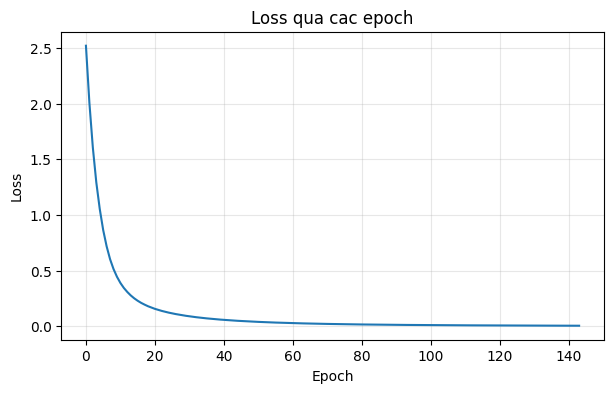

Dung som: epoch= 44 | test accuracy= 0.9577777777777777
Logistic | test accuracy: 0.9711
KNN | test accuracy: 0.9867
SVM | test accuracy: 0.9911


In [6]:
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
Xd,yd=load_digits(return_X_y=True)
Xdtr,Xdte,ydtr,ydte=train_test_split(Xd,yd,test_size=.25,random_state=17,stratify=yd)
mlp_digits=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(100,),max_iter=1000,random_state=0)).fit(Xdtr,ydtr)
net=mlp_digits[-1]
num_params=sum(w.size for w in net.coefs_)+sum(v.size for v in net.intercepts_)
print('Trong so:',[w.shape for w in net.coefs_],'| Tham so:',num_params,'| Vong:',net.n_iter_)
print('Loss vong dau, vong 10, cuoi:',net.loss_curve_[0],net.loss_curve_[min(9,len(net.loss_curve_)-1)],net.loss_curve_[-1])
pdigi=mlp_digits.predict(Xdte)
print('MLP accuracy:',accuracy_score(ydte,pdigi),'| so anh sai:',int(np.sum(pdigi!=ydte)))
plt.figure(figsize=(7,4));plt.plot(net.loss_curve_);plt.title('Loss qua cac epoch');plt.xlabel('Epoch');plt.ylabel('Loss');plt.grid(alpha=.3)
plt.savefig('ket_qua/lab09_buoc5_loss.png',dpi=150,bbox_inches='tight');plt.show()
early=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(100,),max_iter=1000,early_stopping=True,random_state=0)).fit(Xdtr,ydtr)
print('Dung som: epoch=',early[-1].n_iter_,'| test accuracy=',early.score(Xdte,ydte))
for name,m in [('Logistic',make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))),('KNN',KNeighborsClassifier()),('SVM',SVC())]:
    print(name,'| test accuracy:',round(m.fit(Xdtr,ydtr).score(Xdte,ydte),4))

## Phần II — Giải 6 bài tập Lab 09

### Bài tập 1 — Tự dự đoán bằng trọng số MLP 8 nơ-ron

In [7]:
mlp8=mlp_xor_models[8]
Xfive=Xxor_te.to_numpy()[:5]
W_hidden,W_out=mlp8.coefs_
b_hidden,b_out=mlp8.intercepts_
hidden=np.maximum(Xfive@W_hidden+b_hidden,0)
y_manual=1/(1+np.exp(-(hidden@W_out+b_out)))
proba_sklearn=mlp8.predict_proba(Xfive)[:,1]
df_compare=pd.DataFrame({'MLP_proba':proba_sklearn,'Manual_numpy':y_manual.ravel(),'Abs_diff':np.abs(proba_sklearn-y_manual.ravel())})
display(df_compare.round(12))
print('Chenh lech lon nhat:',df_compare.Abs_diff.max())
assert np.allclose(proba_sklearn,y_manual.ravel(),atol=1e-9)
print('Nhan xet: sklearn luu trong so o coefs_ va bias o intercepts_; lan truyen tien tu tay cho ket qua trung.')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MLPClassifier was fitted with feature names
  warnings.warn(


,MLP_proba,Manual_numpy,Abs_diff
0,0.017750,0.017750,0.0
1,0.999460,0.999460,0.0
2,0.799700,0.799700,0.0
3,0.136507,0.136507,0.0
4,0.957766,0.957766,0.0


Chenh lech lon nhat: 0.0
Nhan xet: sklearn luu trong so o coefs_ va bias o intercepts_; lan truyen tien tu tay cho ket qua trung.


### Bài tập 2 — Mạng XOR khác: h1=ReLU(x1−x2), h2=ReLU(x2−x1)

In [8]:
def xor_other(X):
    x1,x2=X[:,0],X[:,1]
    h1=np.maximum(0,x1-x2);h2=np.maximum(0,x2-x1)
    return np.c_[h1,h2,h1+h2]
other=xor_other(Xlogic)
display(pd.DataFrame(np.c_[Xlogic,other],columns=['x1','x2','h1','h2','y']))
assert np.array_equal(other[:,-1],[0,1,1,0])
print('Giai thich: x1=x2 thi hai h bang 0; neu hai bit khac nhau, dung mot neuron bang 1 va y=1.')

,x1,x2,h1,h2,y
0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,1.0,1.0
2,1.0,0.0,1.0,0.0,1.0
3,1.0,1.0,0.0,0.0,0.0


Giai thich: x1=x2 thi hai h bang 0; neu hai bit khac nhau, dung mot neuron bang 1 va y=1.


### Bài tập 3 — So sánh logistic, tanh và relu cho hai lớp ẩn 100 nơ-ron

In [9]:
act_rows=[]
for activation in ['logistic','tanh','relu']:
    m=moon_mlp((100,100),alpha=1.0,activation=activation).fit(Xmtr,ymtr)
    act_rows.append([activation,m.score(Xmtr,ymtr),m.score(Xmte,ymte)])
act=pd.DataFrame(act_rows,columns=['Activation','Train accuracy','Test accuracy']);display(act.round(4))
print('Ham tot nhat tren TEST trong lan thu nay:',act.loc[act['Test accuracy'].idxmax(),'Activation'])
print('Nhan xet: so sanh ket qua chu khong chon tham so bang cach nhin test trong quy trinh dung.')

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF F,G EVALUATIONS EXCEEDS LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,Activation,Train accuracy,Test accuracy
0,logistic,0.8400,0.8533
1,tanh,0.8711,0.9067
2,relu,0.8844,0.9067


Ham tot nhat tren TEST trong lan thu nay: tanh
Nhan xet: so sanh ket qua chu khong chon tham so bang cach nhin test trong quy trinh dung.


### Bài tập 4 — Learning rate và các đường loss trên bộ chữ số

,Learning rate,Epochs,Final loss,Accuracy test
0,0.0001,582,0.01893,0.98889
1,0.0010,144,0.00521,0.98444
2,0.0100,38,0.00108,0.97778
3,0.1000,30,0.20545,0.96000


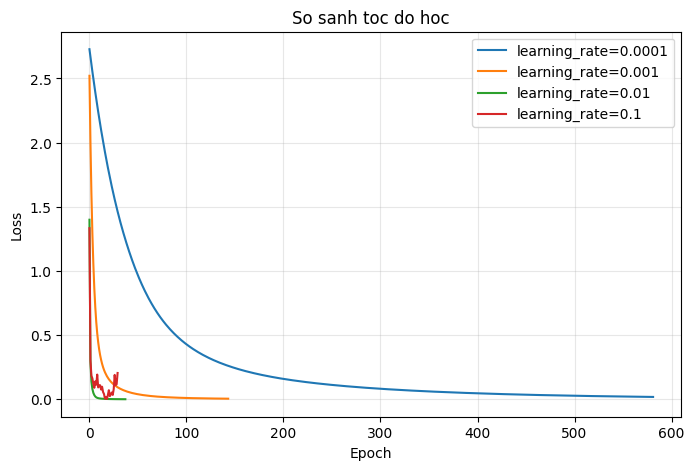

Nhan xet: toc do rat nho -> hoc cham; qua lon -> co the dao dong, khong hoi tu hay giam accuracy.


In [10]:
lr_rows=[]
plt.figure(figsize=(8,5))
for lr in [.0001,.001,.01,.1]:
    m=make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(100,),max_iter=1000,learning_rate_init=lr,random_state=0)).fit(Xdtr,ydtr)
    nn=m[-1];lr_rows.append([lr,nn.n_iter_,nn.loss_curve_[-1],m.score(Xdte,ydte)])
    plt.plot(nn.loss_curve_,label=f'learning_rate={lr}')
display(pd.DataFrame(lr_rows,columns=['Learning rate','Epochs','Final loss','Accuracy test']).round(5))
plt.legend();plt.xlabel('Epoch');plt.ylabel('Loss');plt.title('So sanh toc do hoc');plt.grid(alpha=.3)
plt.savefig('ket_qua/toc_do_hoc.png',dpi=150,bbox_inches='tight');plt.show()
print('Nhan xet: toc do rat nho -> hoc cham; qua lon -> co the dao dong, khong hoi tu hay giam accuracy.')

### Bài tập 5 — Dò lưới hidden_layer_sizes và alpha

12 cấu hình × 3 folds = 36 lượt huấn luyện; dùng tập học để chọn mô hình. `max_iter=500` giúp giảm thời gian trong Colab; tăng lên nếu muốn kiểm tra hội tụ kỹ hơn.

In [11]:
from sklearn.model_selection import GridSearchCV
param_grid={'mlpclassifier__hidden_layer_sizes':[(10,),(50,),(100,),(50,50)],'mlpclassifier__alpha':[.0001,.01,1.]}
search_mlp=GridSearchCV(make_pipeline(StandardScaler(),MLPClassifier(max_iter=500,random_state=0)),param_grid,cv=3,n_jobs=-1,scoring='accuracy')
search_mlp.fit(Xdtr,ydtr)
print('Best params:',search_mlp.best_params_,'| CV accuracy:',round(search_mlp.best_score_,4))
accuracy_mlp=search_mlp.score(Xdte,ydte)
svm_baseline=SVC().fit(Xdtr,ydtr).score(Xdte,ydte)
print('MLP test:',round(accuracy_mlp,4),'| SVM RBF test:',round(svm_baseline,4))
print('MLP vuot SVM?',accuracy_mlp>svm_baseline)
results_grid=pd.DataFrame(search_mlp.cv_results_)[['params','mean_test_score','rank_test_score']].sort_values('rank_test_score')
display(results_grid.head(12))

Best params: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (100,)} | CV accuracy: 0.9777
MLP test: 0.9844 | SVM RBF test: 0.9911
MLP vuot SVM? False


,params,mean_test_score,rank_test_score
10,"{'mlpclassifier__alpha': 1.0, 'mlpclassifier__...",0.977728,1
9,"{'mlpclassifier__alpha': 1.0, 'mlpclassifier__...",0.976244,2
11,"{'mlpclassifier__alpha': 1.0, 'mlpclassifier__...",0.976244,2
2,"{'mlpclassifier__alpha': 0.0001, 'mlpclassifie...",0.974016,4
6,"{'mlpclassifier__alpha': 0.01, 'mlpclassifier_...",0.974016,4
5,"{'mlpclassifier__alpha': 0.01, 'mlpclassifier_...",0.972532,6
1,"{'mlpclassifier__alpha': 0.0001, 'mlpclassifie...",0.972532,6
7,"{'mlpclassifier__alpha': 0.01, 'mlpclassifier_...",0.965850,8
3,"{'mlpclassifier__alpha': 0.0001, 'mlpclassifie...",0.965850,8
8,"{'mlpclassifier__alpha': 1.0, 'mlpclassifier__...",0.953229,10


### Bài tập 6 — MLPRegressor, so MAE với LinearRegression, dự đoán nhà 250 m²

In [12]:
from sklearn.linear_model import LinearRegression
house=pd.read_csv('data/gia_nha.csv'); house_X=house.drop(columns='gia');house_y=house.gia
Xhtr,Xhte,yhtr,yhte=train_test_split(house_X,house_y,test_size=.25,random_state=17)
lin=LinearRegression().fit(Xhtr,yhtr)
mlpr=make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(20,),max_iter=5000,random_state=0)).fit(Xhtr,yhtr)
print('MAE Linear Regression:',mean_absolute_error(yhte,lin.predict(Xhte)))
print('MAE MLPRegressor:',mean_absolute_error(yhte,mlpr.predict(Xhte)))
# Chi thay dien tich=250 m², giu so phong/tuoi nha o trung vi tap hoc de so sanh cong bang
new_house=Xhtr.median().to_frame().T;new_house['dien_tich']=250.
print('Nha du doan (cac cot khac la trung vi tap hoc):',new_house.to_dict('records')[0])
print('Gia du doan Linear:',float(lin.predict(new_house)[0]),'| Gia du doan MLP:',float(mlpr.predict(new_house)[0]))
print('Nhan xet: 250 m² co the nam ngoai mien tap hoc. Linear hoi quy ngoai suy theo duong thang; MLP phi tuyen co the khong ngoai suy on dinh.')

MAE Linear Regression: 0.2185459479114916
MAE MLPRegressor: 0.4242460804510662
Nha du doan (cac cot khac la trung vi tap hoc): {'dien_tich': 250.0, 'so_phong': 2.0, 'tuoi_nha': 14.0}
Gia du doan Linear: 18.468382710833033 | Gia du doan MLP: 20.92593735806434
Nhan xet: 250 m² co the nam ngoai mien tap hoc. Linear hoi quy ngoai suy theo duong thang; MLP phi tuyen co the khong ngoai suy on dinh.
